### Package versions

Run the cell below to record the exact package versions used to generate the results in this notebook.


In [1]:
# --- Environment / package versions (added for reproducibility) ---
import sys
try:
    from importlib.metadata import version, PackageNotFoundError
except ImportError:  # Python < 3.8
    from importlib_metadata import version, PackageNotFoundError
print("Python:", sys.version.split()[0])
for _pkg in ["numpy", "pandas", "scipy", "statsmodels", "matplotlib", "seaborn", "gseapy", "pyliftover", "openpyxl", "requests", "pyBigWig", "pyreadr", "adjustText", "pypdf"]:
    try:
        print(f"{_pkg}: {version(_pkg)}")
    except PackageNotFoundError:
        pass


Python: 3.10.12
numpy: 2.2.6
pandas: 2.3.3
scipy: 1.15.3
statsmodels: 0.14.6
matplotlib: 3.10.9
seaborn: 0.13.2
gseapy: 1.3.1
openpyxl: 3.1.5
requests: 2.34.2
pyreadr: 0.5.6
adjustText: 1.4.0
pypdf: 6.13.1


# Fig. 5B — luciferase reporter assays, linear mixed model

Allele-specific reporter activity at the *SLC38A4* locus, from Cebola *et al.*

**To run:** place this notebook and the `luciferase_data/` folder together, then run top to bottom.
Requires `pandas`, `numpy`, `scipy`, `statsmodels` and `openpyxl`. All paths are relative; no
configuration is needed beyond the constants in section 1.

**Input:** `luciferase_data/Nelisa_luciferase_metadata.xlsx` — one row per well, giving firefly and
renilla luminescence, their ratio, and the relative activity used for plotting. All 96 wells are
analysed; no wells are excluded.

**Why a mixed model.** Each construct was assayed in four technical replicates within each of three
independent experiments. Treating the twelve wells as independent is pseudoreplication: technical
replicates share a plate, a transfection and a passage. Experiment is fitted as a random intercept,
and a second random term allows each construct's activity to shift between runs, so that the
construct contrasts are tested against run-to-run variation rather than well-to-well noise.

**Why on the log scale.** Firefly/renilla ratios are multiplicative and right-skewed, so
differences are modelled on log2(ratio) and a coefficient is a log2 fold-change.

**Why the raw ratio and not "relative activity".** Relative activity divides by the empty vector
mean of the same experiment, which sets the control to 1 and destroys its variance. The random
intercept already absorbs between-experiment scaling, so the raw ratio is modelled and the empty
vector enters as an ordinary level — giving a proper interval for "construct vs empty vector".


## 1. Setup and configuration

In [2]:
import json, re, sys, warnings
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import openpyxl
import statsmodels
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
from scipy import stats

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.width", 220)

XLSX  = Path("luciferase_data/Nelisa_luciferase_metadata.xlsx")
SHEET = "Figure 2C"          # tab name predates the figure renumbering; this is Fig. 5B
HEADER_ROW = 3               # 1-based row holding the column names

# Wells flagged as outliers by Dixon's test when the source file was prepared have a
# blank "Relative activity" cell. They are excluded from both the model and the figure,
# as in the published analysis.
EXCLUDE_OUTLIERS = True

# Which empty vector each assay is compared against.
EMPTY_VECTOR = {"promoter": "pGL4.10", "enhancer": "pGL4.23"}
OUTDIR = Path(".")

print("python", sys.version.split()[0], "| pandas", pd.__version__,
      "| statsmodels", statsmodels.__version__)

python 3.10.12 | pandas 2.3.3 | statsmodels 0.14.6


## 2. Read the per-well data

One row per well: firefly, renilla, their ratio, and the relative activity used for plotting.
Sample names carry the construct and the experiment, e.g. `enhancer rs4994910/T exp2`.

In [3]:
if not XLSX.exists():
    raise FileNotFoundError(f"{XLSX} not found - set XLSX in section 1")

ws = openpyxl.load_workbook(XLSX, data_only=True)[SHEET]
rows = list(ws.iter_rows(min_row=HEADER_ROW + 1, values_only=True))

def parse(sample):
    """'enhancer rs4994910/T exp2' | 'pGL4.10-exp1' -> (construct, experiment)."""
    s = str(sample).strip()
    m = re.search(r"[ -]exp(\d+)$", s)
    if not m:
        raise ValueError(f"cannot find an experiment suffix in {s!r}")
    return s[:m.start()].strip(), f"exp{m.group(1)}"

recs = []
for r in rows:
    if not r or not r[0]:
        continue
    construct, exp = parse(r[0])
    recs.append(dict(construct=construct, experiment=exp, sample_type=str(r[1]).strip(),
                     firefly=r[2], renilla=r[3], ratio=r[4],
                     relative_activity=r[5] if isinstance(r[5], (int, float)) else np.nan))

raw = pd.DataFrame(recs)
raw["outlier"] = raw["relative_activity"].isna()   # Dixon, from the source file

def classify(c):
    if c.startswith("pGL4"):
        return pd.Series(dict(assay="empty", variant=None, allele=None,
                              vector=c.rstrip("-")))
    assay = c.split()[0]                       # 'promoter' | 'enhancer'
    variant, allele = c.split()[1].split("/")
    return pd.Series(dict(assay=assay, variant=variant, allele=allele,
                          vector=EMPTY_VECTOR[assay]))

raw = pd.concat([raw, raw["construct"].apply(classify)], axis=1)
raw["is_risk"] = raw["sample_type"].str.strip().str.lower().eq("risk")
raw["log2_ratio"] = np.log2(raw["ratio"])

print(f"{len(raw)} wells | {raw.experiment.nunique()} experiments | "
      f"{raw.construct.nunique()} constructs | {int(raw.outlier.sum())} flagged outliers")
print()
print(raw.groupby(["assay", "construct", "sample_type"], dropna=False)
      .agg(n_wells=("ratio", "size")).to_string())

96 wells | 3 experiments | 8 constructs | 5 flagged outliers

                                                                n_wells
assay    construct             sample_type                             
empty    pGL4.10               Empty vector (promoterless)           12
         pGL4.23               Empty vector (minimal promoter)       12
enhancer enhancer rs11183620/A Risk                                  12
         enhancer rs11183620/G Non-risk                              12
         enhancer rs4994910/C  Risk                                  12
         enhancer rs4994910/T  Non-risk                              12
promoter promoter rs4994910/C  Risk                                  12
         promoter rs4994910/T  Non-risk                              12


## 3. Quality control

The between-experiment spread is what justifies the random intercept: if runs differ appreciably in
overall signal, wells cannot be pooled across them.


In [4]:
assert (raw["ratio"] > 0).all(), "non-positive ratio - log2 undefined"
assert raw.groupby(["construct", "experiment"]).size().eq(4).all(), "expected 4 wells per group"

if raw["outlier"].any():
    print("excluded as outliers (Dixon's test, as recorded in the source file):")
    print(raw.loc[raw.outlier, ["construct", "experiment", "ratio"]].to_string(index=False))
dat = (raw[~raw.outlier] if EXCLUDE_OUTLIERS else raw).copy()
print(f"\nwells analysed: {len(dat)} of {len(raw)}")

per_exp = dat.groupby("experiment")["log2_ratio"].agg(["mean", "std", "count"])
print("\nbetween-experiment shift in log2(ratio):")
print(per_exp.round(3).to_string())
print(f"range of experiment means: {per_exp['mean'].max() - per_exp['mean'].min():.2f} log2 units "
      f"({2 ** (per_exp['mean'].max() - per_exp['mean'].min()):.1f}-fold)")

summary = (dat.groupby(["assay", "variant", "allele", "construct", "vector"], dropna=False)
           .agg(n_wells=("ratio", "size"),
                geomean_ratio=("log2_ratio", lambda s: 2 ** s.mean()),
                sd_log2=("log2_ratio", "std"),
                mean_relative_activity=("relative_activity", "mean"))
           .reset_index())
summary

excluded as outliers (Dixon's test, as recorded in the source file):
           construct experiment    ratio
             pGL4.10       exp3 0.053927
             pGL4.23       exp1 0.009050
             pGL4.23       exp3 0.053956
promoter rs4994910/C       exp3 0.050792
enhancer rs4994910/T       exp2 0.028048

wells analysed: 91 of 96

between-experiment shift in log2(ratio):
             mean    std  count
experiment                     
exp1       -6.989  1.504     31
exp2       -7.351  1.200     31
exp3       -6.395  1.566     29
range of experiment means: 0.96 log2 units (1.9-fold)


,assay,variant,allele,construct,vector,n_wells,geomean_ratio,sd_log2,mean_relative_activity
0,empty,NaN,NaN,pGL4.10,pGL4.10,11,0.009158,0.713576,1.000000
1,empty,NaN,NaN,pGL4.23,pGL4.23,10,0.004601,0.417587,1.000000
2,enhancer,rs11183620,A,enhancer rs11183620/A,pGL4.23,12,0.004602,1.309172,1.374625
3,enhancer,rs11183620,G,enhancer rs11183620/G,pGL4.23,12,0.003357,1.028154,0.791433
4,enhancer,rs4994910,C,enhancer rs4994910/C,pGL4.23,12,0.008425,1.178095,2.660932
5,enhancer,rs4994910,T,enhancer rs4994910/T,pGL4.23,11,0.058360,0.895745,13.122249
6,promoter,rs4994910,C,promoter rs4994910/C,pGL4.10,11,0.006265,0.291902,0.699457
7,promoter,rs4994910,T,promoter rs4994910/T,pGL4.10,12,0.011183,0.649513,1.166833


## 4. Fit the model

`log2(ratio) ~ construct + (1 | experiment) + (1 | experiment:construct)`

Both random terms matter. The first absorbs plate-to-plate scaling. The second says a given
construct's activity varies from run to run, so the four technical replicates are replicates *of
that run* rather than independent evidence about the construct. Omitting it tests the construct
contrasts against well-to-well noise and the p-values come out too small.

In [5]:
LEVELS = ([v for v in EMPTY_VECTOR.values()]
          + sorted(c for c in dat["construct"].unique() if not c.startswith("pGL4")))
dat["construct"] = pd.Categorical(dat["construct"], categories=LEVELS)

fit = smf.mixedlm("log2_ratio ~ C(construct)", dat, groups=dat["experiment"],
                  vc_formula={"construct_x_experiment": "0 + C(construct)"}).fit(reml=True)

K = fit.k_fe
NAMES = list(fit.params.index)[:K]
sd_cxe = float(np.sqrt(np.ravel(fit.vcomp)[0]))
sd_res = float(np.sqrt(fit.scale))
print(f"wells={len(dat)}  experiments={dat.experiment.nunique()}  fixed-effect terms={K}")
print(f"construct x experiment SD = {sd_cxe:.3f} log2 units")
print(f"residual (technical replicate) SD = {sd_res:.3f}")
print(f"ratio = {sd_cxe / sd_res:.1f}x  <- run-to-run variation relative to well-to-well")
print()
print(fit.summary())

wells=91  experiments=3  fixed-effect terms=8
construct x experiment SD = 0.797 log2 units
residual (technical replicate) SD = 0.565
ratio = 1.4x  <- run-to-run variation relative to well-to-well

                      Mixed Linear Model Regression Results
Model:                     MixedLM         Dependent Variable:         log2_ratio
No. Observations:          91              Method:                     REML      
No. Groups:                3               Scale:                      0.3190    
Min. group size:           29              Log-Likelihood:             -97.1887  
Max. group size:           31              Converged:                  Yes       
Mean group size:           30.3                                                  
---------------------------------------------------------------------------------
                                      Coef.  Std.Err.    z    P>|z| [0.025 0.975]
---------------------------------------------------------------------------------
Inter

## 5. Contrasts

Two contrasts were specified in advance and carry the claims:

1. the non-risk element versus its empty vector — does the fragment have regulatory activity;
2. risk versus non-risk allele in the enhancer context — does the variant change that activity.

These are reported **unadjusted**: they are planned comparisons of two distinct hypotheses, not a
screen, so a false-discovery-rate framework does not apply. The remaining contrasts are reported
for context, and a Benjamini–Hochberg column across all of them is retained so that a reader who
prefers a corrected view has it. All p-values are two-sided.


In [6]:
def _col(label):
    if label == LEVELS[0]:
        return None
    hits = [i for i, n in enumerate(NAMES) if n.endswith(f"T.{label}]")]
    if not hits:
        raise KeyError(f"no fixed-effect term for {label!r}")
    return hits[0]

def contrast(a, b, family, label):
    L = np.zeros((1, K))
    for nm, sign in ((a, 1.0), (b, -1.0)):
        c = _col(nm)
        if c is not None:
            L[0, c] += sign
    t = fit.t_test(L)
    eff = float(np.ravel(t.effect)[0]); p = float(np.ravel(t.pvalue)[0])
    ci = np.ravel(t.conf_int())
    return dict(family=family, contrast=label, a=a, b=b, log2FC=eff, fold_change=2 ** eff,
                ci_low_FC=2 ** float(ci[0]), ci_high_FC=2 ** float(ci[1]), p=p)

tests = []
meta = dat[["construct", "assay", "variant", "allele", "is_risk", "vector"]].drop_duplicates()
for (assay, variant), g in meta.dropna(subset=["variant"]).groupby(["assay", "variant"]):
    risk = g.loc[g.is_risk, "construct"].iloc[0]
    non  = g.loc[~g.is_risk, "construct"].iloc[0]
    tests.append(contrast(risk, non, "allelic",
                          f"{variant} {assay}: {g.loc[g.is_risk,'allele'].iloc[0]} (risk) vs "
                          f"{g.loc[~g.is_risk,'allele'].iloc[0]} (non-risk)"))
for r in meta.dropna(subset=["variant"]).itertuples():
    tests.append(contrast(r.construct, r.vector, "vs empty vector",
                          f"{r.construct} vs {r.vector}"))

PRESPECIFIED = ("rs4994910 enhancer", "enhancer rs4994910/T vs pGL4.23")

res = pd.DataFrame(tests)
res["prespecified"] = res["contrast"].str.startswith(PRESPECIFIED)
# Retained for readers who prefer a corrected view; not used for the reported claims.
res["p_BH_all_contrasts"] = multipletests(res["p"], method="fdr_bh")[1]
res = res.sort_values(["prespecified", "family", "contrast"],
                      ascending=[False, True, True]).reset_index(drop=True)
pd.set_option("display.float_format", lambda x: f"{x:,.4g}")
cols = ["prespecified", "family", "contrast", "log2FC", "fold_change",
        "ci_low_FC", "ci_high_FC", "p", "p_BH_all_contrasts"]
print("PRE-SPECIFIED CONTRASTS (reported unadjusted)")
print(res[res.prespecified][cols].to_string(index=False))
print("\nCONTEXT")
print(res[~res.prespecified][cols].to_string(index=False))

PRE-SPECIFIED CONTRASTS (reported unadjusted)
 prespecified          family                                     contrast  log2FC  fold_change  ci_low_FC  ci_high_FC         p  p_BH_all_contrasts
         True         allelic rs4994910 enhancer: C (risk) vs T (non-risk)  -2.741       0.1496    0.05837      0.3832 7.552e-05           0.0003398
         True vs empty vector              enhancer rs4994910/T vs pGL4.23   3.589        12.03      4.669          31 2.596e-07           2.336e-06

CONTEXT
 prespecified          family                                      contrast   log2FC  fold_change  ci_low_FC  ci_high_FC      p  p_BH_all_contrasts
        False         allelic rs11183620 enhancer: A (risk) vs G (non-risk)   0.4552        1.371     0.5366       3.503 0.5097              0.6553
        False         allelic  rs4994910 promoter: C (risk) vs T (non-risk)  -0.8282       0.5632     0.2198       1.443 0.2317              0.5214
        False vs empty vector              enhancer rs

## 6. Comparison with simpler analyses

The pooled-well t-test ignores experiment structure and is the anti-conservative option; the paired
test on the three experiment means respects it and is the natural fallback if a reviewer objects to
a mixed model fitted on three groups.

In [7]:
cmp = []
for r in res[res.family == "allelic"].itertuples():
    A = dat.loc[dat.construct == r.a, "log2_ratio"]
    B = dat.loc[dat.construct == r.b, "log2_ratio"]
    mA = dat[dat.construct == r.a].groupby("experiment")["log2_ratio"].mean()
    mB = dat[dat.construct == r.b].groupby("experiment")["log2_ratio"].mean()
    common = mA.index.intersection(mB.index)
    cmp.append(dict(contrast=r.contrast,
                    fold_change=r.fold_change,
                    p_mixed_model=r.p,
                    p_welch_pooled_wells=float(stats.ttest_ind(A, B, equal_var=False).pvalue),
                    p_paired_experiment_means=float(
                        stats.ttest_rel(mA[common], mB[common]).pvalue)))
print(pd.DataFrame(cmp).to_string(index=False))

                                     contrast  fold_change  p_mixed_model  p_welch_pooled_wells  p_paired_experiment_means
 rs4994910 enhancer: C (risk) vs T (non-risk)       0.1496      7.552e-05             2.628e-06                     0.1433
rs11183620 enhancer: A (risk) vs G (non-risk)        1.371         0.5097                0.3543                     0.5168
 rs4994910 promoter: C (risk) vs T (non-risk)       0.5632         0.2317              0.001009                    0.07148


## 6b. Figure

Panel B redrawn from the modelled data, in the plotting style used by the other figure notebooks
for this paper (Helvetica, 10 pt, top/right spines removed, editable PDF text). Building the figure
from the same frame the model was fitted to keeps the plot and the statistics in step.


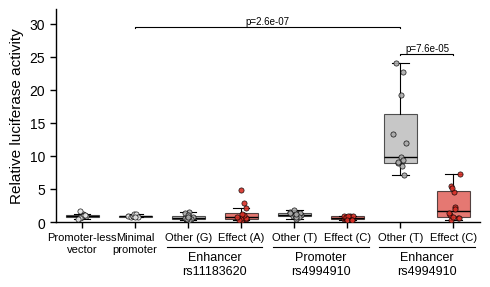

written: Fig5B_luciferase.pdf


In [8]:
import matplotlib.pyplot as plt

# --- shared plotting settings, as in the other figure notebooks for this paper ---
plt.rcParams.update({
    'font.family': 'sans-serif', 'font.sans-serif': ['Helvetica', 'Arial', 'Liberation Sans', 'DejaVu Sans'],
    'font.size': 10, 'axes.linewidth': 1.0,
    'axes.spines.top': False, 'axes.spines.right': False,
    'xtick.major.width': 1.0, 'ytick.major.width': 1.0,
    'xtick.major.size': 4, 'ytick.major.size': 4,
    'savefig.dpi': 300, 'pdf.fonttype': 42, 'ps.fonttype': 42,
    'axes.unicode_minus': False,
})
AXTITLE = 11
C_EMPTY, C_OTHER, C_EFFECT = '#E8E8E8', '#AAAAAA', '#D73027'

def fmt_p(p):
    # house style (matches Fig 3F/3I sig_bracket convention): lowercase p, no
    # spaces around '=', plain scientific notation below 1e-4.
    return f"p={p:.1e}" if p < 1e-4 else f"p={p:.3f}"

# relative activity: ratio / mean ratio of the matching empty vector, within experiment
ctrl = (dat[dat.assay == "empty"].groupby(["experiment", "construct"], observed=True)["ratio"]
        .mean().rename("ctrl").reset_index().rename(columns={"construct": "vector"}))
plotdat = dat.merge(ctrl, on=["experiment", "vector"], how="left")
_self = dat.assay == "empty"
plotdat.loc[_self.values, "ctrl"] = plotdat.loc[_self.values].apply(
    lambda r: float(ctrl.loc[(ctrl.experiment == r.experiment) &
                             (ctrl.vector == r.construct), "ctrl"].iloc[0]), axis=1)
plotdat["relative"] = plotdat["ratio"] / plotdat["ctrl"]

ORDER = ["pGL4.10", "pGL4.23",
         "enhancer rs11183620/G", "enhancer rs11183620/A",
         "promoter rs4994910/T", "promoter rs4994910/C",
         "enhancer rs4994910/T", "enhancer rs4994910/C"]
LAB = ["Promoter-less\nvector", "Minimal\npromoter",
       "Other (G)", "Effect (A)", "Other (T)", "Effect (C)", "Other (T)", "Effect (C)"]
COL = [C_EMPTY, C_EMPTY, C_OTHER, C_EFFECT, C_OTHER, C_EFFECT, C_OTHER, C_EFFECT]

fig, ax = plt.subplots(figsize=(5, 3))
groups = [plotdat.loc[plotdat.construct == c, "relative"].dropna().values for c in ORDER]
bp = ax.boxplot(groups, widths=.62, patch_artist=True, showfliers=False,
                medianprops=dict(color='black', lw=1.0),
                whiskerprops=dict(lw=0.8), capprops=dict(lw=0.8),
                boxprops=dict(lw=0.8))
for patch, col in zip(bp["boxes"], COL):
    patch.set_facecolor(col); patch.set_alpha(0.65); patch.set_edgecolor('black')
rng = np.random.default_rng(0)
for k, (vals, col) in enumerate(zip(groups, COL), 1):
    ax.scatter(rng.normal(k, .06, len(vals)), vals, s=14, color=col,
               edgecolors='black', linewidth=0.5, zorder=4, alpha=0.9)

def p_of(frag):
    return float(res.loc[res.contrast.str.contains(frag, regex=False), "p"].iloc[0])

top = float(np.nanmax(plotdat["relative"]))
ax.set_ylim(0, top * 1.34)
ax.set_xticks(range(1, len(ORDER) + 1)); ax.set_xticklabels(LAB, fontsize=8)
ax.set_ylabel('Relative luciferase activity', fontsize=AXTITLE)
for x0, x1, txt in [(2.5, 4.5, 'Enhancer\nrs11183620'), (4.5, 6.5, 'Promoter\nrs4994910'),
                    (6.5, 8.5, 'Enhancer\nrs4994910')]:
    ax.plot([x0 + .1, x1 - .1], [-0.115, -0.115], 'k-', lw=0.8,
            transform=ax.get_xaxis_transform(), clip_on=False)
    ax.text((x0 + x1) / 2, -0.135, txt, transform=ax.get_xaxis_transform(),
            ha='center', va='top', fontsize=9)
plt.tight_layout()
fig.canvas.draw()  # finalise the layout so the point<->data conversion below is exact

def bracket(a, b, y, p, tick_pt=1.1):
    # Styling matches sig_bracket() in Fig 3F/3I: 0.8pt black line, fontsize 7.
    # The foot height is fixed in *points* (~1.1pt, measured off Fig 3F's own
    # brackets) rather than as a fraction of this axis's data range, so it
    # looks the same size on the page regardless of this panel's y-scale.
    x1, x2 = ORDER.index(a) + 1, ORDER.index(b) + 1
    y_disp = ax.transData.transform((x1, y))[1]
    y_top_disp = y_disp + tick_pt * fig.dpi / 72.0
    h = ax.transData.inverted().transform((x1, y_top_disp))[1] - y
    ax.plot([x1, x1, x2, x2], [y, y + h, y + h, y], color='black', lw=0.8,
            clip_on=False, zorder=5)
    ax.text((x1 + x2) / 2, y + h, fmt_p(p), ha='center', va='bottom', fontsize=7)

top_lim = ax.get_ylim()[1]
headroom = top_lim - top
bracket("enhancer rs4994910/T", "enhancer rs4994910/C", top + headroom * 0.15,
        p_of("rs4994910 enhancer: C (risk) vs T"))
bracket("pGL4.23", "enhancer rs4994910/T", top + headroom * 0.65,
        p_of("enhancer rs4994910/T vs pGL4.23"))

fig.savefig('Fig5B_luciferase.pdf', bbox_inches='tight'); plt.show()
print("written: Fig5B_luciferase.pdf")

## 7. Outputs

In [9]:
raw.to_csv(OUTDIR / "Fig5B_luciferase_wells.csv", index=False)
summary.to_csv(OUTDIR / "Fig5B_luciferase_construct_summary.csv", index=False)
res.to_csv(OUTDIR / "Fig5B_luciferase_contrasts.csv", index=False)

prov = dict(
    generated=datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ"),
    source_file=str(XLSX), sheet=SHEET,
    model="log2(firefly/renilla) ~ construct + (1|experiment) + (1|experiment:construct), REML",
    outlier_exclusion="Dixon test flags from the source file; excluded from model and figure",
    n_wells=int(len(dat)),
    n_experiments=int(dat.experiment.nunique()),
    construct_x_experiment_sd_log2=sd_cxe, residual_sd_log2=sd_res,
    reported_contrasts="two pre-specified contrasts, reported unadjusted",
    multiple_testing="Benjamini-Hochberg across all contrasts retained as a column only",
    versions=dict(python=sys.version.split()[0], pandas=pd.__version__,
                  statsmodels=statsmodels.__version__, numpy=np.__version__),
)
(OUTDIR / "Fig5B_luciferase_provenance.json").write_text(json.dumps(prov, indent=2))
print("written: Fig5B_luciferase_wells.csv, _construct_summary.csv, _contrasts.csv, _provenance.json")

written: Fig5B_luciferase_wells.csv, _construct_summary.csv, _contrasts.csv, _provenance.json


## 8. Notes

- The sheet is named `Figure 2C`, predating the figure renumbering; it is the data behind Fig. 5B.
- Five wells flagged as outliers by Dixon's test in the source file are excluded from both the
  model and the figure, matching the published analysis. Set `EXCLUDE_OUTLIERS = False` to keep
  them; the conclusions are unchanged either way.
- Three experiments is few for a variance component, so the fitted SDs are imprecise. The
  fixed-effect contrasts remain the right comparison and are conservative relative to pooling wells.
- Reporting suggestion: give the fold-change with its confidence interval, state n as the number of
  independent experiments, and name the model in the legend.
- The two pre-specified contrasts also clear Bonferroni correction across all nine contrasts
  (2.1x10^-4 and 3.1x10^-3), so the choice not to adjust does not affect any conclusion.
